# Sampling Steps Impact Analysis — PFGM++ / EDM

This notebook evaluates how the **number of ODE sampling steps** affects generation quality and speed for the PFGM++ model.

For each step count we:
1. Generate CT images from MRI conditioning
2. Measure wall-clock time
3. Compute PSNR / SSIM / MAE (masked to body region)
4. Visualize outputs side-by-side
5. Plot quality-vs-speed tradeoff curves

## 1. Import Libraries and Setup

In [2]:
import os, sys, time
from pathlib import Path
from typing import Tuple, Dict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Ensure project root is importable
PROJECT_ROOT = "/mnt/nvme/lloyd/Swin-pfgm/Swin_pfgm"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# Project imports (these do NOT pull in accelerate)
from models import create_swin_fir_unet
from loader import MonaiNiftiSliceDataset, get_monai_nifti_transforms
from safetensors.torch import load_file as load_safetensors

# Metrics
import torchmetrics

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

/mnt/nvme/lloyd/anaconda3/envs/edm/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/mnt/nvme/lloyd/anaconda3/envs/edm/lib/python3.9/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: libtorch_cuda_cu.so: cannot open shared object file: No such file or directory
  warn(f"Failed to load image Python extension: {e}")


Device: cuda


## 2. Load Configuration and Model

In [3]:
# ---------- Configuration (must match training) ----------
cfg = {
    # Model architecture
    "base_channels": 64,
    "channel_mults": [1, 2, 4, 4],
    "num_res_blocks": 1,
    "attention_resolutions": [4],
    "num_heads": 8,
    "mlp_ratio": 4.0,
    "radius_emb_dim": 256,
    "window_size": 8,
    "num_swin_blocks": 6,
    "num_sfb_blocks": 1,
    "num_bottleneck_blocks": 1,
    "use_sfb": True,
    "dropout": 0.0,
    "drop_path": 0.0,

    # EDM / PFGM++
    "sigma_min": 0.002,
    "sigma_max": 80.0,
    "sigma_data": 0.45,
    "rho": 7.0,
    "pfgmpp": True,
    "D": 128,

    # CFG / CFG++
    "cfg_scale": 2.0,
    "use_cfg_plus_plus": True,
    "cfg_rescale_factor": 0.7,
    "use_dynamic_cfg": True,
    "cfg_scale_min": 1.0,
    "cfg_scale_max": 3.0,

    # Data
    "image_size": 256,
    "data_dir": "/mnt/nvme/lloyd/DL project CT-MRI/pfgm_train_brain_new",
    "mr_pattern": "mr.nii",
    "ct_pattern": "ct.nii",
    "mask_pattern": "mask.nii",
    "use_body_mask": True,
}

CHECKPOINT_PATH = (
    "/mnt/nvme/lloyd/Swin-pfgm/Swin_pfgm/outputs_accelerate/"
    "20260221_213812_pfgm_fir/checkpoints/best/model.safetensors"
)

# ---------- Build model ----------
model = create_swin_fir_unet(
    config="custom",
    in_channels=2,
    out_channels=1,
    base_channels=cfg["base_channels"],
    channel_mults=cfg["channel_mults"],
    num_res_blocks=cfg["num_res_blocks"],
    attention_resolutions=cfg["attention_resolutions"],
    num_heads=cfg["num_heads"],
    mlp_ratio=cfg["mlp_ratio"],
    radius_emb_dim=cfg["radius_emb_dim"],
    window_size=cfg["window_size"],
    num_swin_blocks=cfg["num_swin_blocks"],
    num_sfb_blocks=cfg["num_sfb_blocks"],
    num_bottleneck_blocks=cfg["num_bottleneck_blocks"],
    use_sfb=cfg["use_sfb"],
    dropout=cfg["dropout"],
    drop_path_rate=cfg["drop_path"],
)

# ---------- Load weights ----------
state_dict = load_safetensors(CHECKPOINT_PATH)
# Strip "module." prefix if saved from DDP/FSDP
if any(k.startswith("module.") for k in state_dict):
    state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}

model.load_state_dict(state_dict)
model = model.to(device).eval()

total_params = sum(p.numel() for p in model.parameters())
print(f"Model loaded: {total_params / 1e6:.2f}M parameters")
print(f"Checkpoint : {CHECKPOINT_PATH}")

Model loaded: 38.22M parameters
Checkpoint : /mnt/nvme/lloyd/Swin-pfgm/Swin_pfgm/outputs_accelerate/20260221_213812_pfgm_fir/checkpoints/best/model.safetensors


## 3. Load Sample Data

In [4]:
# ---------- Inline collect_data_files (avoids pulling in accelerate at import) ----------
def collect_data_files(data_path, mr_pattern="mr.nii", ct_pattern="ct.nii",
                       mask_pattern="mask.nii", use_body_mask=False):
    data_files = []
    for patient_dir in sorted(os.listdir(data_path)):
        patient_path = os.path.join(data_path, patient_dir)
        if not os.path.isdir(patient_path):
            continue
        mr_file = ct_file = mask_file = None
        for fn in os.listdir(patient_path):
            if mr_pattern in fn:
                mr_file = os.path.join(patient_path, fn)
            if ct_pattern in fn:
                ct_file = os.path.join(patient_path, fn)
            if use_body_mask and mask_pattern in fn:
                mask_file = os.path.join(patient_path, fn)
        if mr_file and ct_file:
            entry = {"mr": mr_file, "ct": ct_file, "id": patient_dir}
            if use_body_mask:
                entry["mask"] = mask_file
            data_files.append(entry)
    return data_files

# ---------- Gather all patient files ----------
all_files = collect_data_files(
    cfg["data_dir"],
    mr_pattern=cfg["mr_pattern"],
    ct_pattern=cfg["ct_pattern"],
    mask_pattern=cfg["mask_pattern"],
    use_body_mask=cfg["use_body_mask"],
)
print(f"Found {len(all_files)} patients")

# Use a few patients for demonstration
NUM_SAMPLES = 4
sample_files = all_files[:NUM_SAMPLES]

# ---------- Create dataset (val mode = no augmentation) ----------
val_transforms = get_monai_nifti_transforms(
    mode="val", target_size=cfg["image_size"], use_body_mask=cfg["use_body_mask"]
)
sample_dataset = MonaiNiftiSliceDataset(
    data=sample_files,
    transform=val_transforms,
    target_size=cfg["image_size"],
    use_body_mask=cfg["use_body_mask"],
)

# Pick slices near the middle of each patient's volume (more anatomy)
# The slice_map is [(file_idx, slice_idx), ...] — find mid-slice per patient
chosen_indices = []
for file_i in range(NUM_SAMPLES):
    patient_slices = [i for i, (fi, _) in enumerate(sample_dataset.slice_map) if fi == file_i]
    mid = patient_slices[len(patient_slices) // 2]
    chosen_indices.append(mid)

# Load chosen slices
mr_batch, ct_batch, mask_batch = [], [], []
for idx in chosen_indices:
    sample = sample_dataset[idx]
    mr_batch.append(sample["mr"])
    ct_batch.append(sample["ct"])
    if "mask" in sample:
        mask_batch.append(sample["mask"])

mr_batch = torch.stack(mr_batch).to(device)
ct_batch = torch.stack(ct_batch).to(device)
mask_batch = torch.stack(mask_batch).to(device) if mask_batch else None

print(f"MR  batch: {mr_batch.shape}, range [{mr_batch.min():.3f}, {mr_batch.max():.3f}]")
print(f"CT  batch: {ct_batch.shape}, range [{ct_batch.min():.3f}, {ct_batch.max():.3f}]")
if mask_batch is not None:
    print(f"Mask batch: {mask_batch.shape}, body coverage: {mask_batch.mean():.2%}")

Found 303 patients
Pre-scanning NIfTI files to create slice map (using ALL slices)...
  Patient 1BA001: 163 slices
  Patient 1BA005: 164 slices
  Patient 1BA012: 157 slices
  Patient 1BA014: 139 slices
Total slices in dataset: 623
Body mask loading ENABLED - will load mask files for anatomically-focused training


/mnt/nvme/lloyd/anaconda3/envs/edm/lib/python3.9/site-packages/monai/utils/deprecate_utils.py:321: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


MR  batch: torch.Size([4, 1, 256, 256]), range [-1.000, 1.000]
CT  batch: torch.Size([4, 1, 256, 256]), range [-0.999, 1.000]
Mask batch: torch.Size([4, 1, 256, 256]), body coverage: 64.07%


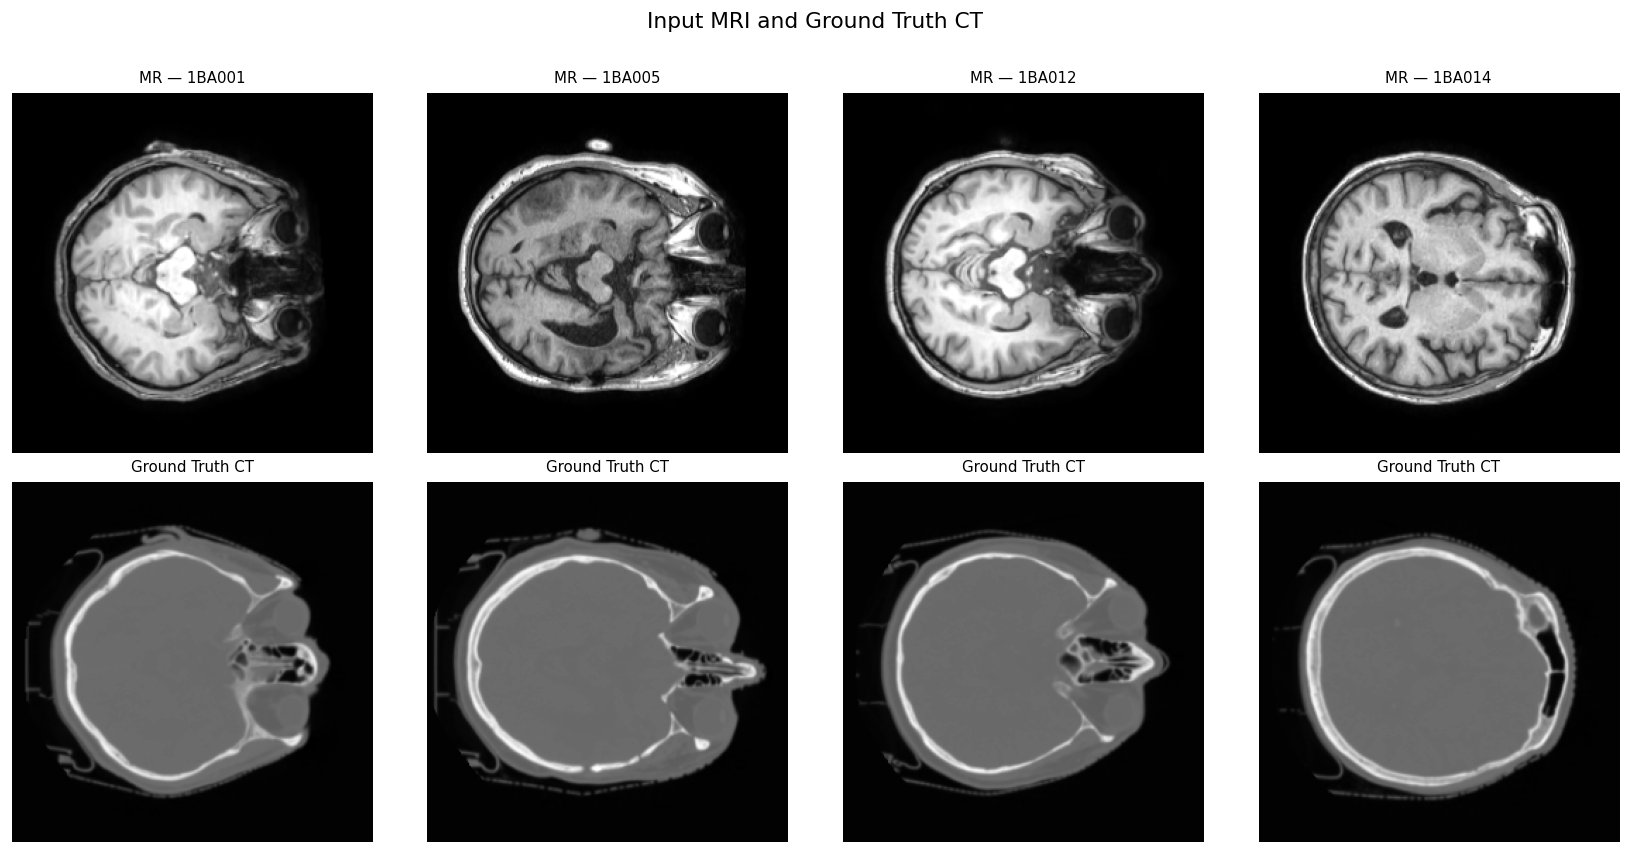

In [5]:
# ---------- Display input MR and ground-truth CT ----------
fig, axes = plt.subplots(2, NUM_SAMPLES, figsize=(3.5 * NUM_SAMPLES, 7))
for i in range(NUM_SAMPLES):
    axes[0, i].imshow(mr_batch[i, 0].cpu().numpy(), cmap="gray", vmin=-1, vmax=1)
    axes[0, i].set_title(f"MR — {sample_files[i]['id']}", fontsize=9)
    axes[0, i].axis("off")

    axes[1, i].imshow(ct_batch[i, 0].cpu().numpy(), cmap="gray", vmin=-1, vmax=1)
    axes[1, i].set_title("Ground Truth CT", fontsize=9)
    axes[1, i].axis("off")

fig.suptitle("Input MRI and Ground Truth CT", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 4. Define Sampling Helper Functions

In [6]:
# ========================  Inlined sampling functions  ========================
# (Copied from train_accelerate.py to avoid importing the accelerate dependency)

def edm_precond(model, x, mri, sigma, sigma_data=0.5):
    """Apply EDM preconditioning to model output."""
    x, mri, sigma = x.float(), mri.float(), sigma.float()
    sigma_4d = sigma.view(-1, 1, 1, 1)
    c_skip = sigma_data ** 2 / (sigma_4d ** 2 + sigma_data ** 2)
    c_out  = sigma_4d * sigma_data / (sigma_4d ** 2 + sigma_data ** 2).sqrt()
    c_in   = 1.0 / (sigma_4d ** 2 + sigma_data ** 2).sqrt()
    c_noise = sigma.log() / 4
    F_x = model(c_in * x, mri, c_noise)
    return c_skip * x + c_out * F_x


def apply_cfg_plus_plus(denoised_cond, denoised_uncond, cfg_scale, rescale_factor=0.7):
    """CFG++ with manifold constraints (rescaling)."""
    denoised_cfg = denoised_uncond + cfg_scale * (denoised_cond - denoised_uncond)
    if rescale_factor > 0:
        std_cond = denoised_cond.std(dim=[1, 2, 3], keepdim=True)
        std_cfg  = denoised_cfg.std(dim=[1, 2, 3], keepdim=True)
        rescale  = std_cond / (std_cfg + 1e-8)
        denoised_cfg = rescale_factor * (denoised_cfg * rescale) + (1 - rescale_factor) * denoised_cfg
    return denoised_cfg


def pfgmpp_sample_prior(batch_size, channels, height, width, sigma_max, D, device,
                         dtype=torch.float64):
    """Sample from PFGM++ prior distribution for ODE initialization."""
    N = channels * height * width
    r_max = sigma_max * np.sqrt(D)
    samples_norm = np.random.beta(a=N / 2.0, b=D / 2.0, size=batch_size).astype(np.float64)
    samples_norm = torch.from_numpy(samples_norm).to(device)
    inverse_beta = samples_norm / (1 - samples_norm + 1e-8)
    radius = r_max * torch.sqrt(inverse_beta + 1e-8)
    gaussian = torch.randn(batch_size, N, device=device, dtype=torch.float64)
    unit_gaussian = gaussian / (torch.norm(gaussian, p=2, dim=1, keepdim=True) + 1e-8)
    latent = (unit_gaussian * radius.view(batch_size, 1)).view(batch_size, channels, height, width)
    return latent.to(dtype)


@torch.no_grad()
def edm_sample(
    model, mri, num_steps=50,
    sigma_min=0.002, sigma_max=80.0, sigma_data=0.5, rho=7.0,
    S_churn=0.0, S_min=0.0, S_max=float("inf"), S_noise=1.0,
    cfg_scale=1.0, pfgmpp=False, D=128,
    use_cfg_plus_plus=False, cfg_rescale_factor=0.7,
    use_dynamic_cfg=False, cfg_scale_min=1.0, cfg_scale_max=3.0,
):
    """Heun ODE sampler with PFGM++ / CFG++ / dynamic CFG."""
    B, C, H, W = mri.shape
    device = mri.device

    step_indices = torch.arange(num_steps, dtype=torch.float64, device=device)
    t_steps = (
        sigma_max ** (1 / rho)
        + step_indices / (num_steps - 1) * (sigma_min ** (1 / rho) - sigma_max ** (1 / rho))
    ) ** rho
    t_steps = torch.cat([t_steps, torch.zeros_like(t_steps[:1])])

    if pfgmpp:
        x_next = pfgmpp_sample_prior(B, 1, H, W, sigma_max, D, device, torch.float64)
    else:
        x_next = torch.randn(B, 1, H, W, device=device, dtype=torch.float64) * t_steps[0]

    mri_uncond = torch.zeros_like(mri) if cfg_scale != 1.0 or use_dynamic_cfg else None

    for i, (t_cur, t_next) in enumerate(zip(t_steps[:-1], t_steps[1:])):
        x_cur = x_next

        if use_dynamic_cfg:
            progress = i / (num_steps - 1)
            current_cfg = cfg_scale_max + progress * (cfg_scale_min - cfg_scale_max)
        else:
            current_cfg = cfg_scale

        gamma = min(S_churn / num_steps, np.sqrt(2) - 1) if S_min <= t_cur <= S_max else 0
        t_hat = t_cur + gamma * t_cur
        x_hat = x_cur + (t_hat ** 2 - t_cur ** 2).sqrt() * S_noise * torch.randn_like(x_cur)

        sigma_b = torch.full((B,), t_hat.item(), device=device, dtype=torch.float32)
        denoised_cond = edm_precond(model, x_hat.float(), mri, sigma_b, sigma_data).double()

        if current_cfg != 1.0:
            denoised_uncond = edm_precond(model, x_hat.float(), mri_uncond, sigma_b, sigma_data).double()
            if use_cfg_plus_plus:
                denoised = apply_cfg_plus_plus(denoised_cond, denoised_uncond,
                                               current_cfg, cfg_rescale_factor)
            else:
                denoised = denoised_uncond + current_cfg * (denoised_cond - denoised_uncond)
        else:
            denoised = denoised_cond

        d_cur = (x_hat - denoised) / t_hat
        x_next = x_hat + (t_next - t_hat) * d_cur

        # Heun 2nd-order correction
        if i < num_steps - 1 and t_next > 0:
            sigma_b2 = torch.full((B,), t_next.item(), device=device, dtype=torch.float32)
            dec2 = edm_precond(model, x_next.float(), mri, sigma_b2, sigma_data).double()
            if current_cfg != 1.0:
                duc2 = edm_precond(model, x_next.float(), mri_uncond, sigma_b2, sigma_data).double()
                if use_cfg_plus_plus:
                    den2 = apply_cfg_plus_plus(dec2, duc2, current_cfg, cfg_rescale_factor)
                else:
                    den2 = duc2 + current_cfg * (dec2 - duc2)
            else:
                den2 = dec2
            d_prime = (x_next - den2) / t_next
            x_next = x_hat + (t_next - t_hat) * (0.5 * d_cur + 0.5 * d_prime)

    return x_next.float()


# ========================  Experiment wrappers  ========================

def generate_with_steps(model, mri, num_steps, cfg):
    """Run edm_sample with the given number of ODE steps."""
    return edm_sample(
        model, mri,
        num_steps=num_steps,
        sigma_min=cfg["sigma_min"], sigma_max=cfg["sigma_max"],
        sigma_data=cfg["sigma_data"], rho=cfg["rho"],
        cfg_scale=cfg["cfg_scale"], pfgmpp=cfg["pfgmpp"], D=cfg["D"],
        use_cfg_plus_plus=cfg["use_cfg_plus_plus"],
        cfg_rescale_factor=cfg["cfg_rescale_factor"],
        use_dynamic_cfg=cfg["use_dynamic_cfg"],
        cfg_scale_min=cfg["cfg_scale_min"],
        cfg_scale_max=cfg["cfg_scale_max"],
    )


def run_step_experiment(model, mri, step_list, cfg):
    """Generate images at each step count and record wall-clock time."""
    results = {}
    for steps in step_list:
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.time()
        pred = generate_with_steps(model, mri, steps, cfg)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        elapsed = time.time() - t0
        results[steps] = {"images": pred.cpu(), "time_s": elapsed}
        print(f"  Steps {steps:>3d}  —  {elapsed:.2f}s")
    return results

print("Sampling and helper functions defined.")

Sampling and helper functions defined.


## 5. Run Generation with Different Step Counts

In [7]:
STEP_LIST = [5, 10, 15, 20, 25, 35, 50, 75, 100]

print(f"Running generation for step counts: {STEP_LIST}")
print(f"Batch size: {mr_batch.shape[0]} samples\n")

results = run_step_experiment(model, mr_batch, STEP_LIST, cfg)

# Summary table
print(f"\n{'Steps':>6s}  {'Time (s)':>9s}  {'s/sample':>9s}")
print("-" * 30)
B = mr_batch.shape[0]
for s in STEP_LIST:
    t = results[s]["time_s"]
    print(f"{s:>6d}  {t:>9.2f}  {t/B:>9.3f}")

Running generation for step counts: [5, 10, 15, 20, 25, 35, 50, 75, 100]
Batch size: 4 samples

  Steps   5  —  2.42s
  Steps  10  —  4.62s
  Steps  15  —  7.14s
  Steps  20  —  9.63s
  Steps  25  —  12.17s
  Steps  35  —  17.23s
  Steps  50  —  24.94s
  Steps  75  —  37.80s
  Steps 100  —  50.49s

 Steps   Time (s)   s/sample
------------------------------
     5       2.42      0.604
    10       4.62      1.156
    15       7.14      1.784
    20       9.63      2.409
    25      12.17      3.044
    35      17.23      4.308
    50      24.94      6.235
    75      37.80      9.449
   100      50.49     12.623


## 6. Compute Metrics Across Step Counts

In [8]:
# Initialize metrics on the correct device
psnr_metric = torchmetrics.image.PeakSignalNoiseRatio(data_range=1.0).to(device)
ssim_metric = torchmetrics.image.StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
mae_metric  = torchmetrics.MeanAbsoluteError().to(device)

# Ground truth in [0, 1]
ct_01 = ((ct_batch + 1.0) / 2.0).clamp(0, 1)
mask_dev = mask_batch.to(device) if mask_batch is not None else None

metrics_table = {}  # step → {psnr, ssim, mae, time_s, per_sample_psnr}

for steps in STEP_LIST:
    pred = results[steps]["images"].to(device)
    pred_01 = ((pred + 1.0) / 2.0).clamp(0, 1)

    # Apply body mask if available
    if mask_dev is not None:
        pred_masked = pred_01 * mask_dev
        ct_masked = ct_01 * mask_dev
    else:
        pred_masked = pred_01
        ct_masked = ct_01

    psnr_val = psnr_metric(pred_masked, ct_masked).item()
    ssim_val = ssim_metric(pred_masked, ct_masked).item()
    mae_val  = mae_metric(pred_masked, ct_masked).item()

    # Per-sample PSNR for variance
    per_sample_psnr = []
    for i in range(pred_masked.shape[0]):
        ps = psnr_metric(pred_masked[i:i+1], ct_masked[i:i+1]).item()
        per_sample_psnr.append(ps)

    metrics_table[steps] = {
        "psnr": psnr_val,
        "ssim": ssim_val,
        "mae": mae_val,
        "time_s": results[steps]["time_s"],
        "per_sample_psnr": per_sample_psnr,
    }

    # Reset metric states
    psnr_metric.reset()
    ssim_metric.reset()
    mae_metric.reset()

# ---------- Pretty-print ----------
mask_tag = " (masked)" if mask_dev is not None else ""
print(f"\n{'Steps':>6s}  {'PSNR':>7s}  {'SSIM':>7s}  {'MAE':>8s}  {'Time (s)':>9s}{mask_tag}")
print("-" * 50)
for s in STEP_LIST:
    m = metrics_table[s]
    print(f"{s:>6d}  {m['psnr']:>7.2f}  {m['ssim']:>7.4f}  {m['mae']:>8.5f}  {m['time_s']:>9.2f}")


 Steps     PSNR     SSIM       MAE   Time (s) (masked)
--------------------------------------------------
     5    13.40   0.4156   0.13367       2.42
    10    26.13   0.8666   0.01770       4.62
    15    25.79   0.8692   0.01806       7.14
    20    26.83   0.8770   0.01646       9.63
    25    26.61   0.8819   0.01632      12.17
    35    26.75   0.8845   0.01599      17.23
    50    26.26   0.8831   0.01658      24.94
    75    26.42   0.8844   0.01618      37.80
   100    26.82   0.8905   0.01544      50.49


## 7. Visualize Generated Images Side by Side

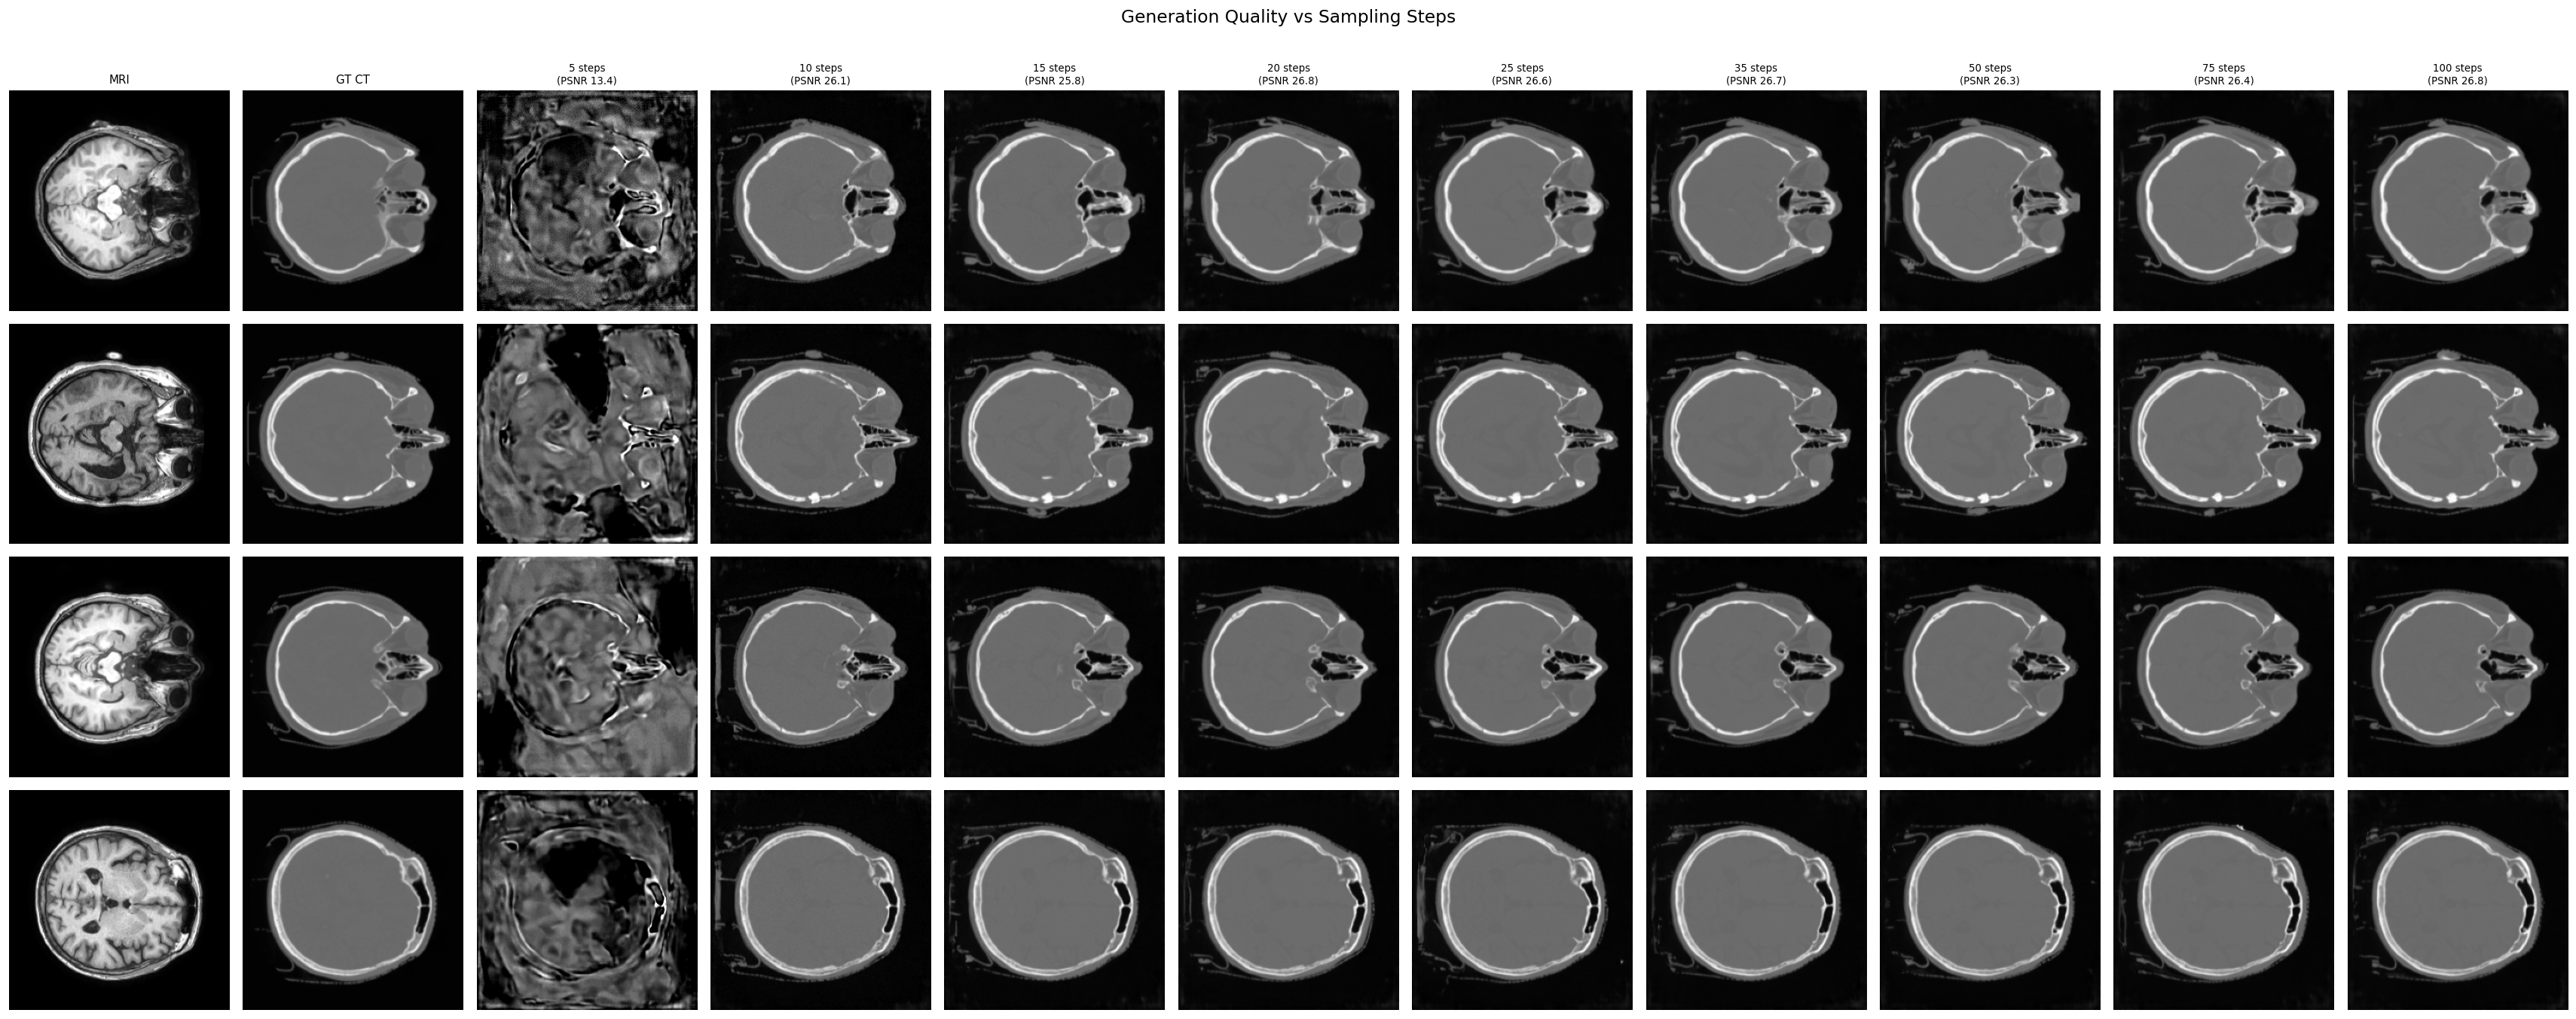

Figure saved to sampling_steps_comparison.png


In [9]:
# Columns: MRI | GT CT | step_1 | step_2 | ...
n_cols = 2 + len(STEP_LIST)
n_rows = NUM_SAMPLES
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.6 * n_cols, 2.8 * n_rows))

for row in range(n_rows):
    # MRI input
    axes[row, 0].imshow(mr_batch[row, 0].cpu().numpy(), cmap="gray", vmin=-1, vmax=1)
    if row == 0:
        axes[row, 0].set_title("MRI", fontsize=9)
    axes[row, 0].set_ylabel(sample_files[row]["id"], fontsize=8)
    axes[row, 0].axis("off")

    # Ground truth CT
    axes[row, 1].imshow(ct_batch[row, 0].cpu().numpy(), cmap="gray", vmin=-1, vmax=1)
    if row == 0:
        axes[row, 1].set_title("GT CT", fontsize=9)
    axes[row, 1].axis("off")

    # Generated CT at each step count
    for ci, steps in enumerate(STEP_LIST):
        img = results[steps]["images"][row, 0].numpy()
        axes[row, ci + 2].imshow(img, cmap="gray", vmin=-1, vmax=1)
        if row == 0:
            psnr_s = metrics_table[steps]["psnr"]
            axes[row, ci + 2].set_title(f"{steps} steps\n(PSNR {psnr_s:.1f})", fontsize=8)
        axes[row, ci + 2].axis("off")

fig.suptitle("Generation Quality vs Sampling Steps", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("sampling_steps_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved to sampling_steps_comparison.png")

## 8. Plot Metrics vs Number of Steps

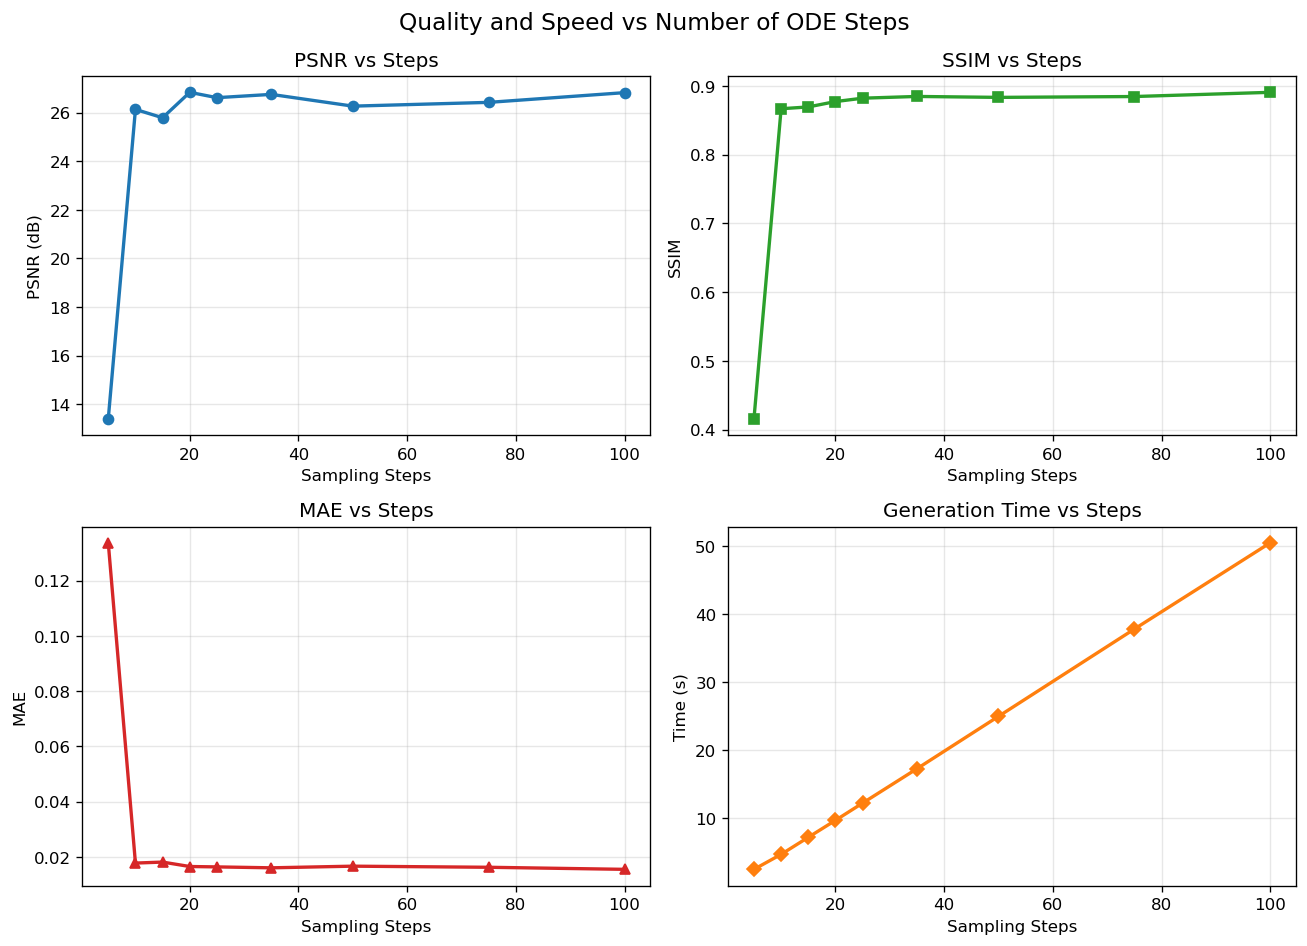

Figure saved to metrics_vs_steps.png


In [10]:
steps_arr = np.array(STEP_LIST)
psnr_arr  = np.array([metrics_table[s]["psnr"]   for s in STEP_LIST])
ssim_arr  = np.array([metrics_table[s]["ssim"]   for s in STEP_LIST])
mae_arr   = np.array([metrics_table[s]["mae"]    for s in STEP_LIST])
time_arr  = np.array([metrics_table[s]["time_s"] for s in STEP_LIST])

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# PSNR
axes[0, 0].plot(steps_arr, psnr_arr, "o-", color="tab:blue", linewidth=2)
axes[0, 0].set_xlabel("Sampling Steps")
axes[0, 0].set_ylabel("PSNR (dB)")
axes[0, 0].set_title("PSNR vs Steps")
axes[0, 0].grid(True, alpha=0.3)

# SSIM
axes[0, 1].plot(steps_arr, ssim_arr, "s-", color="tab:green", linewidth=2)
axes[0, 1].set_xlabel("Sampling Steps")
axes[0, 1].set_ylabel("SSIM")
axes[0, 1].set_title("SSIM vs Steps")
axes[0, 1].grid(True, alpha=0.3)

# MAE
axes[1, 0].plot(steps_arr, mae_arr, "^-", color="tab:red", linewidth=2)
axes[1, 0].set_xlabel("Sampling Steps")
axes[1, 0].set_ylabel("MAE")
axes[1, 0].set_title("MAE vs Steps")
axes[1, 0].grid(True, alpha=0.3)

# Time
axes[1, 1].plot(steps_arr, time_arr, "D-", color="tab:orange", linewidth=2)
axes[1, 1].set_xlabel("Sampling Steps")
axes[1, 1].set_ylabel("Time (s)")
axes[1, 1].set_title("Generation Time vs Steps")
axes[1, 1].grid(True, alpha=0.3)

fig.suptitle("Quality and Speed vs Number of ODE Steps", fontsize=14)
plt.tight_layout()
plt.savefig("metrics_vs_steps.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved to metrics_vs_steps.png")

## 9. Quality-per-Second Analysis and Recommendation

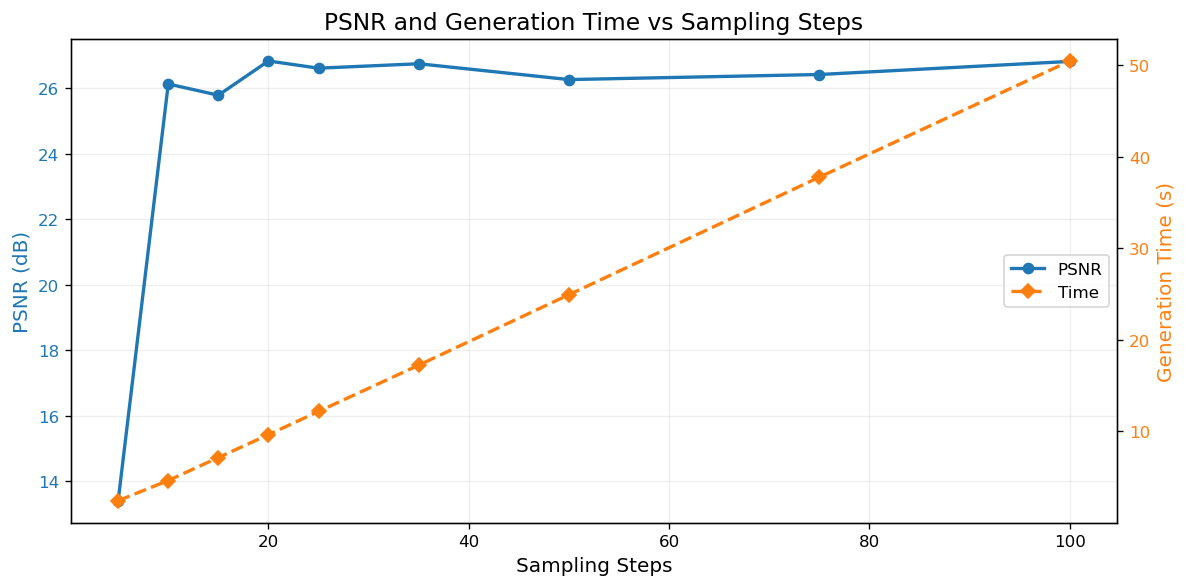


 Steps     PSNR   Time(s)    PSNR/s
-----------------------------------
     5    13.40      2.42      5.54
    10    26.13      4.62      5.65
    15    25.79      7.14      3.61
    20    26.83      9.63      2.78
    25    26.61     12.17      2.19
    35    26.75     17.23      1.55
    50    26.26     24.94      1.05
    75    26.42     37.80      0.70
   100    26.82     50.49      0.53

--- Diminishing Returns ---
  From →   To    ΔPSNR   ΔSteps   ΔPSNR/step
------------------------------------------
     5 →   10  +12.730        5       2.5460
    10 →   15   -0.343        5      -0.0687  ← diminishing
    15 →   20   +1.046        5       0.2091
    20 →   25   -0.220        5      -0.0440  ← diminishing
    25 →   35   +0.135       10       0.0135  ← diminishing
    35 →   50   -0.484       15      -0.0322  ← diminishing
    50 →   75   +0.155       25       0.0062  ← diminishing
    75 →  100   +0.400       25       0.0160  ← diminishing

★ Best PSNR/s efficiency : 10 steps

In [11]:
# ---------- Dual-axis plot: quality + time ----------
fig, ax1 = plt.subplots(figsize=(10, 5))

color_psnr = "tab:blue"
color_time = "tab:orange"

ax1.set_xlabel("Sampling Steps", fontsize=12)
ax1.set_ylabel("PSNR (dB)", color=color_psnr, fontsize=12)
ln1 = ax1.plot(steps_arr, psnr_arr, "o-", color=color_psnr, linewidth=2, label="PSNR")
ax1.tick_params(axis="y", labelcolor=color_psnr)
ax1.grid(True, alpha=0.2)

ax2 = ax1.twinx()
ax2.set_ylabel("Generation Time (s)", color=color_time, fontsize=12)
ln2 = ax2.plot(steps_arr, time_arr, "D--", color=color_time, linewidth=2, label="Time")
ax2.tick_params(axis="y", labelcolor=color_time)

lns = ln1 + ln2
labels = [l.get_label() for l in lns]
ax1.legend(lns, labels, loc="center right", fontsize=10)
plt.title("PSNR and Generation Time vs Sampling Steps", fontsize=14)
plt.tight_layout()
plt.savefig("quality_vs_time.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- Efficiency metric: PSNR per second ----------
efficiency = psnr_arr / time_arr

print(f"\n{'Steps':>6s}  {'PSNR':>7s}  {'Time(s)':>8s}  {'PSNR/s':>8s}")
print("-" * 35)
for i, s in enumerate(STEP_LIST):
    print(f"{s:>6d}  {psnr_arr[i]:>7.2f}  {time_arr[i]:>8.2f}  {efficiency[i]:>8.2f}")

# ---------- Diminishing returns analysis ----------
# Marginal PSNR gain per additional step
print("\n--- Diminishing Returns ---")
print(f"{'From':>6s} → {'To':>4s}  {'ΔPSNR':>7s}  {'ΔSteps':>7s}  {'ΔPSNR/step':>11s}")
print("-" * 42)
for i in range(1, len(STEP_LIST)):
    dp = psnr_arr[i] - psnr_arr[i - 1]
    ds = steps_arr[i] - steps_arr[i - 1]
    gain_per_step = dp / ds if ds > 0 else 0
    marker = "  ← diminishing" if gain_per_step < 0.02 else ""
    print(f"{STEP_LIST[i-1]:>6d} → {STEP_LIST[i]:>4d}  {dp:>+7.3f}  {ds:>7.0f}  {gain_per_step:>11.4f}{marker}")

# Find best efficiency step
best_eff_idx = int(np.argmax(efficiency))
# Find "knee" — first step where marginal gain/step < 0.02 dB
knee_idx = None
for i in range(1, len(STEP_LIST)):
    dp = psnr_arr[i] - psnr_arr[i - 1]
    ds = steps_arr[i] - steps_arr[i - 1]
    if dp / ds < 0.02:
        knee_idx = i - 1
        break
if knee_idx is None:
    knee_idx = len(STEP_LIST) - 1

print(f"\n★ Best PSNR/s efficiency : {STEP_LIST[best_eff_idx]} steps "
      f"({efficiency[best_eff_idx]:.2f} PSNR/s)")
print(f"★ Diminishing-returns knee: {STEP_LIST[knee_idx]} steps "
      f"(PSNR {psnr_arr[knee_idx]:.2f} dB)")
print(f"★ Recommended sweet spot : {STEP_LIST[knee_idx]} steps")